In [1]:
# Install required libraries in the current Jupyter kernel
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


# Advanced Air Pollution Analysis & City-Level Prediction


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re

import warnings
warnings.filterwarnings('ignore')
pd.set_option('future.no_silent_downcasting', True)



## 1. Robust Data Processing

Handling inconsistent columns from datasets 2020 to 2023. This approach identifies the core parameters cleanly.


In [3]:

files = {
    2020: "dataset---2020.csv",
    2021: "dataset---2021.csv",
    2022: "dataset---2022.csv",
    2023: "dataset---2023.csv"
}

dfs = []

def clean_column_names(cols):
    cleaned = []
    for col in cols:
        # Lowercase and remove all non-alphanumeric chars to find matches
        c = re.sub(r'[^a-zA-Z0-9]', '', str(col).lower())
        if 'state' in c:
            cleaned.append('State')
        elif 'city' in c or 'town' in c:
            cleaned.append('City')
        elif 'so2' in c:
            cleaned.append('SO2')
        elif 'no2' in c:
            cleaned.append('NO2')
        elif 'pm10' in c:
            cleaned.append('PM10')
        elif 'pm25' in c:
            cleaned.append('PM25')
        elif 'year' in c:
            cleaned.append('Year_Drop') # We manually add year below
        else:
            cleaned.append(col)
    return cleaned

for year, file in files.items():
    if os.path.exists(file):
        df = pd.read_csv(file)
        df.columns = clean_column_names(df.columns)
        if 'Year_Drop' in df.columns:
            df.drop('Year_Drop', axis=1, inplace=True)
        # Assign explicit year
        df['Year'] = year
        
        # Keep only desired columns to ensure structured concat
        target_cols = ['Year', 'State', 'City', 'SO2', 'NO2', 'PM10', 'PM25']
        
        # Add missing columns with NaN to avoid errors
        for col in target_cols:
            if col not in df.columns:
                df[col] = np.nan
        
        # Filter to exact columns and append
        dfs.append(df[target_cols])

final_df = pd.concat(dfs, ignore_index=True)

# Replace 'NM', '-', 'NA', empty strings with NaN
final_df.replace(['NM', '-', 'NA', ' ', ''], np.nan, inplace=True)

# Force numeric values on pollutants
pollutants = ['SO2', 'NO2', 'PM10', 'PM25']
for p in pollutants:
    final_df[p] = pd.to_numeric(final_df[p], errors='coerce')

final_df['City'] = final_df['City'].str.strip().str.title()
final_df['State'] = final_df['State'].str.strip().str.title()

print(f"Combined Data Shape: {final_df.shape}")
final_df.head()



Combined Data Shape: (1714, 7)


,Year,State,City,SO2,NO2,PM10,PM25
0,2020,Andhra Pradesh,Adjacent,5.0,11.0,NaN,NaN
1,2020,Andhra Pradesh,Annual,6.0,15.0,NaN,NaN
2,2020,Andhra Pradesh,Apparao,8.0,13.0,NaN,NaN
3,2020,Andhra Pradesh,Autonagar,5.0,17.0,NaN,NaN
4,2020,Andhra Pradesh,Bamunimaidam,8.0,13.0,NaN,NaN


## 2. Advanced Imputation & Feature Engineering

Imputing based on the **City** or **State** averages, and calculating an **Air Quality Proxy (AQI_Proxy)**.


In [4]:

# 1. First impute missing values by City average
for col in pollutants:
    final_df[col] = final_df.groupby('City')[col].transform(lambda x: x.fillna(x.mean()))

# 2. If City is still missing (very rare), impute by State average
for col in pollutants:
    final_df[col] = final_df.groupby('State')[col].transform(lambda x: x.fillna(x.mean()))

# 3. If State is missing, use National average
for col in pollutants:
    final_df[col] = final_df[col].fillna(final_df[col].mean())

# Verify no NaNs remain in pollutants
print("Null values\n", final_df.isnull().sum())

# Create AQI Proxy
# Since true AQI formula is complex and stepwise, we'll use a normalized weighted sum proxy
final_df['AQI_Proxy'] = (
    final_df['PM25'] * 0.4 + 
    final_df['PM10'] * 0.3 + 
    final_df['NO2'] * 0.2 + 
    final_df['SO2'] * 0.1
)

final_df.head()



Null values
 Year     0
State    0
City     5
SO2      0
NO2      0
PM10     0
PM25     0
dtype: int64


,Year,State,City,SO2,NO2,PM10,PM25,AQI_Proxy
0,2020,Andhra Pradesh,Adjacent,5.0,11.0,64.919872,29.25641,33.878526
1,2020,Andhra Pradesh,Annual,6.0,15.0,64.919872,29.25641,34.778526
2,2020,Andhra Pradesh,Apparao,8.0,13.0,64.919872,29.25641,34.578526
3,2020,Andhra Pradesh,Autonagar,5.0,17.0,64.919872,29.25641,35.078526
4,2020,Andhra Pradesh,Bamunimaidam,8.0,13.0,64.919872,29.25641,34.578526


## 3. Data Visualizations & Analytics


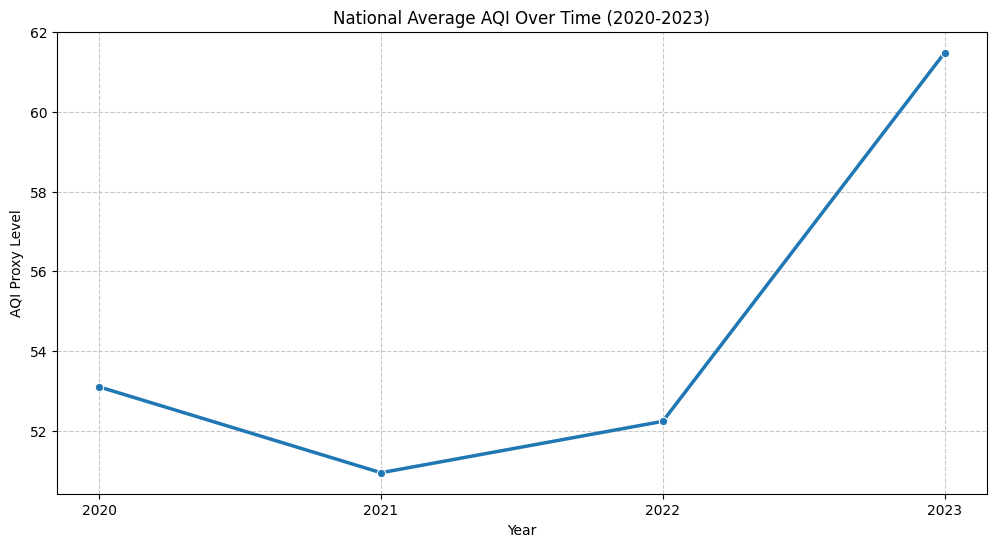

In [5]:

plt.figure(figsize=(12, 6))
sns.lineplot(data=final_df, x='Year', y='AQI_Proxy', marker='o', ci=None, linewidth=2.5)
plt.title('National Average AQI Over Time (2020-2023)')
plt.ylabel('AQI Proxy Level')
plt.xlabel('Year')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks([2020, 2021, 2022, 2023])
plt.show()



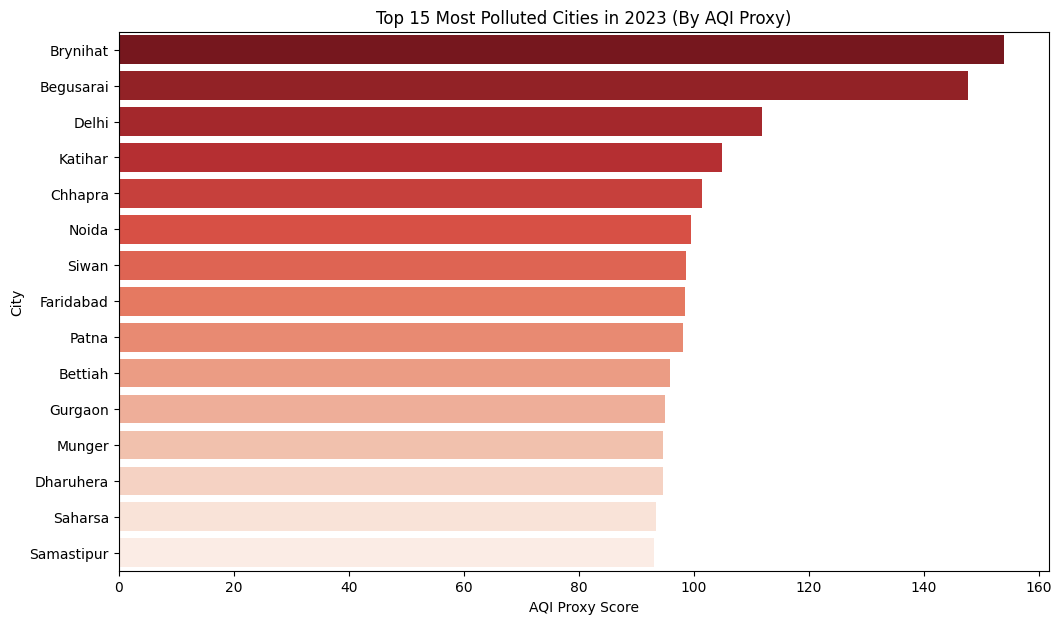

In [6]:

top_cities_2023 = final_df[final_df['Year'] == 2023].groupby('City')['AQI_Proxy'].mean().sort_values(ascending=False).head(15)

plt.figure(figsize=(12, 7))
sns.barplot(x=top_cities_2023.values, y=top_cities_2023.index, palette='Reds_r')
plt.title('Top 15 Most Polluted Cities in 2023 (By AQI Proxy)')
plt.xlabel('AQI Proxy Score')
plt.ylabel('City')
plt.show()



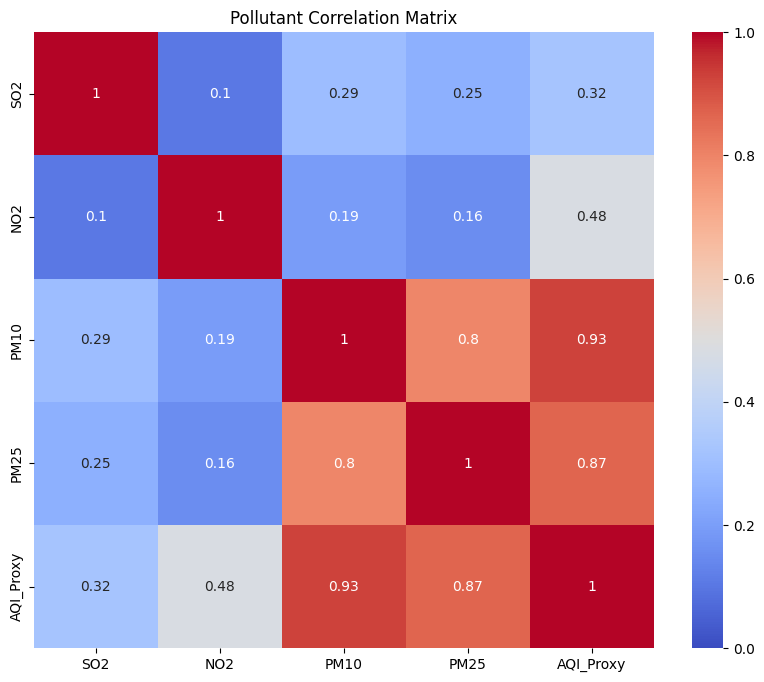

In [7]:

plt.figure(figsize=(10, 8))
corr = final_df[pollutants + ['AQI_Proxy']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=0, vmax=1)
plt.title('Pollutant Correlation Matrix')
plt.show()



## 4. Machine Learning Model (Random Forest)

We will build a Random Forest Regressor to predict the `PM25` values based on geographical location & year.


In [8]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score

# Copy data
ml_df = final_df.dropna(subset=['City', 'State']).copy()

# Encoding categorical variables
le_city = LabelEncoder()
le_state = LabelEncoder()

ml_df['City_Code'] = le_city.fit_transform(ml_df['City'])
ml_df['State_Code'] = le_state.fit_transform(ml_df['State'])

# Features & Target
# Let's predict PM25 (the most dangerous pollutant) using Time & Geography
X = ml_df[['Year', 'State_Code', 'City_Code']]
y = ml_df['PM25']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Model Evaluation (Predicting PM2.5)")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared Score (R2): {r2:.2f}")



Model Evaluation (Predicting PM2.5)
Mean Squared Error (MSE): 116.18
R-squared Score (R2): 0.64


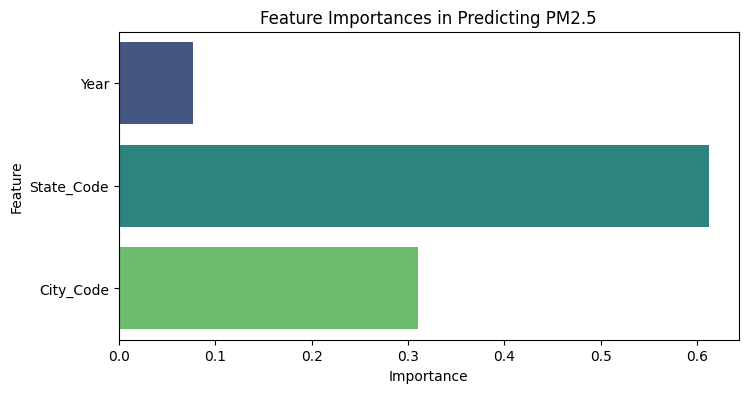

In [9]:

# Feature Importance
importances = rf_model.feature_importances_
features = X.columns

plt.figure(figsize=(8, 4))
sns.barplot(x=importances, y=features, palette='viridis')
plt.title('Feature Importances in Predicting PM2.5')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()



## 5. Future Predictions


In [10]:

# Predict 2024 PM2.5 for a specific City (e.g., Delhi)

def predict_future_pollution(city_name, year):
    if city_name not in le_city.classes_:
        return f"City '{city_name}' not found in training data."
    
    city_code = le_city.transform([city_name])[0]
    # Find matching state
    state_code = ml_df[ml_df['City_Code'] == city_code]['State_Code'].values[0]
    
    # Predict
    pred = rf_model.predict([[year, state_code, city_code]])
    return pred[0]

# Testing the predictor for the top 3 most common cities in dataset
sample_cities = ml_df['City'].value_counts().head(3).index.tolist()

print("Predictions for 2024 PM2.5 Levels:\n")
for city in sample_cities:
    pred_2024 = predict_future_pollution(city, 2024)
    print(f"- {city}: {pred_2024:.2f} µg/m3")



Predictions for 2024 PM2.5 Levels:

- General: 35.39 µg/m3
- Annual: 39.24 µg/m3
- Near: 32.39 µg/m3
